1 - IMPORT Des Fichiers

In [1]:
import pandas as pd
import numpy as np
import unicodedata

from pathlib import Path

base = Path.cwd()
if base.name == "Notebooks":
    base = base.parent
data_dir = base / "Données p11"
if not data_dir.is_dir():
    raise FileNotFoundError("Lancer le notebook depuis le dossier P11 ou Notebooks.")

# IMPORT DES DONNÉES

df_fao = pd.read_csv(data_dir / "FAO_2017.csv", encoding='utf-8')
df_pop = pd.read_csv(data_dir / "Population 2017.csv", sep=';')
df_pop_grow = pd.read_csv(data_dir / "Croissance 2017.csv", sep=';')
df_urbanisation = pd.read_csv(data_dir / "Urbanisation 2017.csv", sep=';')
df_urb_grow = pd.read_csv(data_dir / "Croissance Urbaine 2017.csv", sep=';')
df_gdp = pd.read_csv(data_dir / "PIB Hab 2017.csv", sep=';')
df_stability = pd.read_csv(data_dir / "Stabilité Politique 2017.csv", sep=';', low_memory=False)
df_regulation = pd.read_csv(data_dir / "Qualite Regulation 2017.csv", sep=';', low_memory=False)
country_ref = pd.read_csv(data_dir / "countries_translation.csv")




Justification des fichiers sélectionnés selon PESTEL: 
PIB_hab — reflète la capacité économique d’un pays à consommer ou importer de la volaille (Economique).
Croissance_Pop — indique la pression démographique sur la demande alimentaire future (Social).
Urbanisation — mesure l’évolution vers des modes de consommation modernes et structurés (S/E).
Croissance_Urb — signale la vitesse d’adoption des régimes alimentaires urbains, plus riches en volaille (S).
Stabilite_Politique — conditionne la sécurité des chaînes logistiques et la production agricole (Politique).
Qualite_Regulation — reflète la solidité des normes sanitaires et des politiques agroalimentaires (P/Légal).

2 - Nettoyage

In [2]:
# RENOMMAGE DES COLONNES POUR UNIFORMITÉ


# Urbanisation
df_urbanisation = df_urbanisation.rename(columns={
    "Urban (%)": "Urbanisation"
})

# Croissance urbaine
df_urb_grow = df_urb_grow.rename(columns={
    "Growth (%)": "Croissance_Urb"
})

# Croissance population
df_pop_grow = df_pop_grow.rename(columns={
    "Growth": "Croissance_Pop"
})

# PIB par habitant
df_gdp = df_gdp.rename(columns={
    "Amount": "PIB_hab"
})

# Population
df_pop = df_pop.rename(columns={
    "Valeur": "Population"
})

# Stabilité politique (WGI)
df_stability = df_stability.rename(columns={
    "Governance estimate (approx. -2.5 to +2.5)": "Stabilite_Politique"
})

# Régulation (WGI)
df_regulation = df_regulation.rename(columns={
    "Governance estimate (approx. -2.5 to +2.5)": "Qualite_Regulation"
})


In [3]:
# NORMALISATION + MAPPING FR/EN

def normalize_country_name(x):
    if pd.isna(x):
        return np.nan
    s = str(x).strip().lower()
    s = unicodedata.normalize("NFKD", s)
    s = "".join(ch for ch in s if not unicodedata.combining(ch))
    s = s.replace("&", " and ").replace(".", "").replace("'", "").replace("-", " ").replace(",", " ")
    s = " ".join(s.split())
    return s

# Normaliser CSV FR↔EN
country_ref["Country_FR_norm"] = country_ref["Country_FR"].map(normalize_country_name)
country_ref["Country_EN_norm"] = country_ref["Country_EN"].map(normalize_country_name)

mapping_en_to_fr = dict(zip(country_ref["Country_EN_norm"], country_ref["Country_FR_norm"]))

# Liste de tous les dataframes
dfs = [
    df_fao,
    df_pop,
    df_pop_grow,
    df_urbanisation,
    df_urb_grow,
    df_gdp,
    df_stability,
    df_regulation
]

# Normaliser et mapper pour TOUS les dataframes
for df in dfs:
    # Normalisation
    df["Zone_norm"] = df["Zone"].map(normalize_country_name)

    # Mapping EN → FR
    df["Zone_FR"] = df["Zone_norm"].map(mapping_en_to_fr)

    # Si pas trouvé dans le mapping, garder la version normalisée
    df["Zone_FR"] = df["Zone_FR"].fillna(df["Zone_norm"])



In [4]:
# SUPPRESSION DES DOUBLONS + SÉLECTION DES COLONNES


df_fao = df_fao[["Zone_FR", "Élément", "Produit", "Valeur", "Année"]].drop_duplicates()

df_pop = df_pop[["Zone_FR", "Population"]].drop_duplicates(subset="Zone_FR", keep="last")
df_pop_grow = df_pop_grow[["Zone_FR", "Croissance_Pop"]].drop_duplicates(subset="Zone_FR", keep="last")
df_urbanisation = df_urbanisation[["Zone_FR", "Urbanisation"]].drop_duplicates(subset="Zone_FR", keep="last")
df_urb_grow = df_urb_grow[["Zone_FR", "Croissance_Urb"]].drop_duplicates(subset="Zone_FR", keep="last")
df_gdp = df_gdp[["Zone_FR", "PIB_hab"]].drop_duplicates(subset="Zone_FR", keep="last")

df_stability = df_stability[["Zone_FR", "Stabilite_Politique"]].drop_duplicates(subset="Zone_FR", keep="last")
df_regulation = df_regulation[["Zone_FR", "Qualite_Regulation"]].drop_duplicates(subset="Zone_FR", keep="last")


3 - Verification de l'uniformité des datasets

In [5]:
# FILTRER LES PAYS COMMUNS 


# Récupérer les pays dans chaque dataset
fao_countries = set(df_fao["Zone_FR"].dropna().unique())
pop_countries = set(df_pop["Zone_FR"].dropna().unique())
pop_grow_countries = set(df_pop_grow["Zone_FR"].dropna().unique())
urb_countries = set(df_urbanisation["Zone_FR"].dropna().unique())
urb_grow_countries = set(df_urb_grow["Zone_FR"].dropna().unique())
gdp_countries = set(df_gdp["Zone_FR"].dropna().unique())
stability_countries = set(df_stability["Zone_FR"].dropna().unique())
regulation_countries = set(df_regulation["Zone_FR"].dropna().unique())

# Intersection : pays présents dans toutes les tables
common_countries = (
    fao_countries
    & pop_countries
    & pop_grow_countries
    & urb_countries
    & urb_grow_countries
    & gdp_countries
    & stability_countries
    & regulation_countries
)

# Filtrer tous les dataframes pour garder uniquement les pays communs
df_fao = df_fao[df_fao["Zone_FR"].isin(common_countries)].copy()
df_pop = df_pop[df_pop["Zone_FR"].isin(common_countries)].copy()
df_pop_grow = df_pop_grow[df_pop_grow["Zone_FR"].isin(common_countries)].copy()
df_urbanisation = df_urbanisation[df_urbanisation["Zone_FR"].isin(common_countries)].copy()
df_urb_grow = df_urb_grow[df_urb_grow["Zone_FR"].isin(common_countries)].copy()
df_gdp = df_gdp[df_gdp["Zone_FR"].isin(common_countries)].copy()
df_regulation = df_regulation[df_regulation["Zone_FR"].isin(common_countries)].copy()
df_stability = df_stability[df_stability["Zone_FR"].isin(common_countries)].copy()

print(f"Pays communs à tous les datasets : {len(common_countries)}")
print(f"Exemples : {sorted(list(common_countries))[:10]}")


Pays communs à tous les datasets : 168
Exemples : ['afghanistan', 'afrique du sud', 'albanie', 'algerie', 'allemagne', 'angola', 'antigua et barbuda', 'arabie saoudite', 'argentine', 'armenie']


4 - Fusion Des Datsets

In [6]:
# FILTRAGE FAO + MERGE FINAL


# Produits à garder
produits_a_garder = ["Viande de Volailles"]

# Éléments FAO à garder
elements_a_garder = [
    "Production",
    "Importations - Quantité",
    "Exportations - Quantité",
    "Disponibilité alimentaire (Kcal/personne/jour)",
    "Disponibilité alimentaire en quantité (kg/personne/an)"
]

# Filtrer FAO
df_fao_filtered = df_fao[
    df_fao["Élément"].isin(elements_a_garder)
    & df_fao["Produit"].isin(produits_a_garder)
].copy()

print(f"FAO filtré : {len(df_fao_filtered)} lignes")
print(df_fao_filtered["Élément"].unique())
print(df_fao_filtered["Produit"].unique())


# MERGE FINAL SUR Zone_FR

df_merged = df_fao_filtered.merge(df_pop, on="Zone_FR", how="inner")
df_merged = df_merged.merge(df_pop_grow, on="Zone_FR", how="inner")
df_merged = df_merged.merge(df_urbanisation, on="Zone_FR", how="inner")
df_merged = df_merged.merge(df_urb_grow, on="Zone_FR", how="inner")
df_merged = df_merged.merge(df_gdp, on="Zone_FR", how="inner")
df_merged = df_merged.merge(df_stability, on="Zone_FR", how="inner")
df_merged = df_merged.merge(df_regulation, on="Zone_FR", how="inner")

print("\nShape final :", df_merged.shape)
print("Colonnes :", df_merged.columns.tolist())


FAO filtré : 793 lignes
['Production' 'Importations - Quantité'
 'Disponibilité alimentaire en quantité (kg/personne/an)'
 'Disponibilité alimentaire (Kcal/personne/jour)'
 'Exportations - Quantité']
['Viande de Volailles']

Shape final : (793, 12)
Colonnes : ['Zone_FR', 'Élément', 'Produit', 'Valeur', 'Année', 'Population', 'Croissance_Pop', 'Urbanisation', 'Croissance_Urb', 'PIB_hab', 'Stabilite_Politique', 'Qualite_Regulation']


5 - Corerections mathématiques

In [7]:
#multiplication de la colonne population
df_merged["Population"] = df_merged["Population"] * 1000  # Convertir en nombre réel

In [8]:
# arrondir toutes les valeurs numériques à 2 décimales
for col in df_merged.select_dtypes(include=['float64', 'int64']).columns:
    df_merged[col] = df_merged[col].round(2)


6 - Construction du Dataset Final

In [9]:
# PIVOT FAO → 1 LIGNE PAR PAYS


# Garder uniquement les colonnes utiles
df_fao_pivot = df_fao_filtered[["Zone_FR", "Élément", "Valeur"]].copy()

# Pivot : Élément → colonnes
df_fao_pivot = df_fao_pivot.pivot_table(
    index="Zone_FR",
    columns="Élément",
    values="Valeur",
    aggfunc="last"
).reset_index()

# Renommer les colonnes FAO pour ACP
df_fao_pivot = df_fao_pivot.rename(columns={
    "Production": "Poulet_Production",
    "Importations - Quantité": "Poulet_Import",
    "Exportations - Quantité": "Poulet_Export",
    "Disponibilité alimentaire (Kcal/personne/jour)": "Poulet_Kcal_jour",
    "Disponibilité alimentaire en quantité (kg/personne/an)": "Poulet_Dispo_kg_hab"
})

print("Pivot FAO :", df_fao_pivot.shape)
print(df_fao_pivot.head())


Pivot FAO : (167, 6)
Élément         Zone_FR  Poulet_Kcal_jour  Poulet_Dispo_kg_hab  Poulet_Export  \
0           afghanistan               5.0                 1.53            NaN   
1        afrique du sud             143.0                35.69           63.0   
2               albanie              85.0                16.36            0.0   
3               algerie              22.0                 6.38            0.0   
4             allemagne              71.0                19.47          646.0   

Élément  Poulet_Import  Poulet_Production  
0                 29.0               28.0  
1                514.0             1667.0  
2                 38.0               13.0  
3                  2.0              275.0  
4                842.0             1514.0  


In [10]:
# CONSTRUCTION DU DATASET

# Sélection des colonnes socio-éco
df_final = df_merged[
    [
        'Zone_FR',
        'Population',
        'Croissance_Pop',
        'Urbanisation',
        'Croissance_Urb',
        'PIB_hab',
        'Stabilite_Politique',
        'Qualite_Regulation'
    ]
].drop_duplicates()

# Ajouter les données FAO pivotées
df_final = df_final.merge(
    df_fao_pivot[
        [
            'Zone_FR',
            'Poulet_Production',
            'Poulet_Import',
            'Poulet_Export',
            'Poulet_Dispo_kg_hab',
            'Poulet_Kcal_jour'
        ]
    ],
    on='Zone_FR',
    how='inner'
)

# Calculer les valeurs nettes (kg)
df_final["Poulet_Production_kg"] = df_final["Poulet_Production"] * 1_000_000
df_final["Poulet_Import_kg"] = df_final["Poulet_Import"] * 1_000_000
df_final["Poulet_Export_kg"] = df_final["Poulet_Export"] * 1_000_000

# Rapporter à l'habitant
df_final["Production_volaille_hab"] = df_final["Poulet_Production_kg"] / df_final["Population"]
df_final["Importations_volaille_hab"] = df_final["Poulet_Import_kg"] / df_final["Population"]
df_final["Exportations_volaille_hab"] = df_final["Poulet_Export_kg"] / df_final["Population"]

# Disponibilité alimentaire déjà en kg/hab
df_final["Disponibilite_alimentaire_kg_hab"] = df_final["Poulet_Dispo_kg_hab"]

# Nettoyage final
df_final = df_final[
    [
        'Zone_FR',
        'Population',
        'PIB_hab',
        'Croissance_Pop',
        'Urbanisation',
        'Croissance_Urb',
        'Stabilite_Politique',
        'Qualite_Regulation',
        'Production_volaille_hab',
        'Importations_volaille_hab',
        'Exportations_volaille_hab',
        'Disponibilite_alimentaire_kg_hab',
        'Poulet_Kcal_jour'
    ]
].drop_duplicates().reset_index(drop=True)

# Arrondir les valeurs numériques
type_numeric = df_final.select_dtypes(include=['float64', 'int64']).columns
df_final[type_numeric] = df_final[type_numeric].round(2)

print(df_final.head())
print(df_final.shape)


          Zone_FR  Population   PIB_hab  Croissance_Pop  Urbanisation  \
0     afghanistan  36296113.0    525.47            2.81         24.84   
1  afrique du sud  57009756.0   6618.34            0.65         63.33   
2         albanie   2884169.0   5006.36           -1.54         55.98   
3         algerie  41389189.0   4554.67            2.03         71.32   
4       allemagne  82658409.0  45553.93            0.37         80.98   

   Croissance_Urb  Stabilite_Politique  Qualite_Regulation  \
0            3.52                -2.61               -1.42   
1            0.74                -0.38                0.23   
2           -0.81                 0.16                0.11   
3            2.86                -0.93               -0.95   
4            0.56                 0.70                1.69   

   Production_volaille_hab  Importations_volaille_hab  \
0                     0.77                       0.80   
1                    29.24                       9.02   
2                

Justification des indicateurs :
Production_volaille_hab — mesure la capacité d’offre interne d’un pays (Supply).
Importations_volaille_hab — indique la dépendance externe et la pression de la demande locale (Demand).
Exportations_volaille_hab — révèle la compétitivité internationale et la structure de l’offre (Supply).
Disponibilite_alimentaire_kg_hab — quantifie l’accès réel à la volaille pour la population (S/Demand).
Poulet_Kcal_jour — mesure la contribution nutritionnelle de la volaille dans le régime alimentaire (S).

In [11]:
# Exporter le dataframe final vers un fichier CSV
output_path = data_dir / "df_final.csv"
df_final.to_csv(output_path, index=False)

7 - Correction sur les pays qui pourraient fausser l'analyse

In [12]:
#identifier les pays avec valeurs manquantes dans les colonnes critiques
colonnes_critique = [
    'PIB_hab',
    'Croissance_Pop',
    'Urbanisation',
    'Croissance_Urb',
    'Production_volaille_hab',
    'Importations_volaille_hab',
    'Exportations_volaille_hab',
    'Disponibilite_alimentaire_kg_hab',
    'Kcal_volaille'
]
print("Pays avec valeurs manquantes dans les colonnes critiques :")
for col in colonnes_critique:
    colonne_df = "Poulet_Kcal_jour" if col == "Kcal_volaille" else col

    if colonne_df not in df_final.columns:
        raise KeyError(f"Colonne absente de df_final : {colonne_df}")

    missing_countries = df_final.loc[
        df_final[colonne_df].isna(), "Zone_FR"
    ].tolist()
    if missing_countries:
        print(f"{col}: {missing_countries}")

Pays avec valeurs manquantes dans les colonnes critiques :
PIB_hab: ['republique populaire democratique de coree']
Production_volaille_hab: ['djibouti', 'maldives', 'ouzbekistan', 'republique democratique populaire lao']
Importations_volaille_hab: ['ouzbekistan', 'republique democratique populaire lao']
Exportations_volaille_hab: ['afghanistan', 'bahamas', 'bangladesh', 'burkina faso', 'cabo verde', 'cambodge', 'cuba', 'djibouti', 'ethiopie', 'gambie', 'grenade', 'guinee', 'guinee bissau', 'haiti', 'kiribati', 'madagascar', 'malawi', 'maldives', 'mali', 'mauritanie', 'mongolie', 'mozambique', 'nepal', 'ouzbekistan', 'republique centrafricaine', 'republique democratique populaire lao', 'republique unie de tanzanie', 'sainte lucie', 'saint vincent et les grenadines', 'sao tome et principe', 'soudan', 'tadjikistan', 'timor leste', 'turkmenistan', 'vanuatu', 'zimbabwe']


In [13]:
#Remplacer les valeurs manququantes en exportaitons, importations et production par 0 
df_final['Exportations_volaille_hab'] = df_final['Exportations_volaille_hab'].fillna(0)
df_final['Importations_volaille_hab'] = df_final['Importations_volaille_hab'].fillna(0)
df_final['Production_volaille_hab'] = df_final['Production_volaille_hab'].fillna(0)

In [14]:
# exclure les pays avec des valeurs manquantes dans les colonnes critiques
pays_a_exclure = [
    "republique democratique populaire lao",
    "ouzbekistan",
    "republique populaire democratique de coree",  # Corée du Nord, PIB manquant
]

df_final = df_final[~df_final["Zone_FR"].isin(pays_a_exclure)].reset_index(drop=True)

print(f"{len(pays_a_exclure)} pays exclus, {len(df_final)} pays restants dans l'analyse")

3 pays exclus, 164 pays restants dans l'analyse


3 pays exclus de l'analyse pour absence de données fiables sur des indicateurs structurants (Ouzbékistan et Laos : production et importations de volaille toutes deux non déclarées ; Corée du Nord : PIB non disponible, connu pour son opacité statistique)

8 - DATASET Propre

In [15]:
# exporter le dataframe final nettoyé vers un fichier CSV
output_path_cleaned = data_dir / "df_final_cleaned.csv"
df_final.to_csv(output_path_cleaned, index=False)

In [16]:
# Dimensions
print(df_final.shape)

# Valeurs manquantes
print(df_final.isna().sum())

# Doublons
print(df_final['Zone_FR'].duplicated().sum())

# Statistiques
print(df_final.describe().T)

(164, 13)
Zone_FR                             0
Population                          0
PIB_hab                             0
Croissance_Pop                      0
Urbanisation                        0
Croissance_Urb                      0
Stabilite_Politique                 0
Qualite_Regulation                  0
Production_volaille_hab             0
Importations_volaille_hab           0
Exportations_volaille_hab           0
Disponibilite_alimentaire_kg_hab    0
Poulet_Kcal_jour                    0
dtype: int64
0
                                  count          mean           std       min  \
Population                        164.0  4.418213e+07  1.566297e+08  52045.00   
PIB_hab                           164.0  1.387004e+04  1.884418e+04    432.32   
Croissance_Pop                    164.0  1.195000e+00  1.289686e+00     -2.61   
Urbanisation                      164.0  5.903817e+01  2.178301e+01     15.96   
Croissance_Urb                    164.0  1.856829e+00  1.843423e+00     -2.3

9 - Exploration 

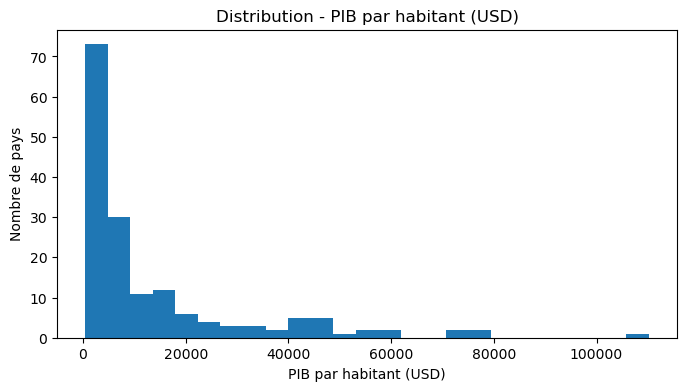

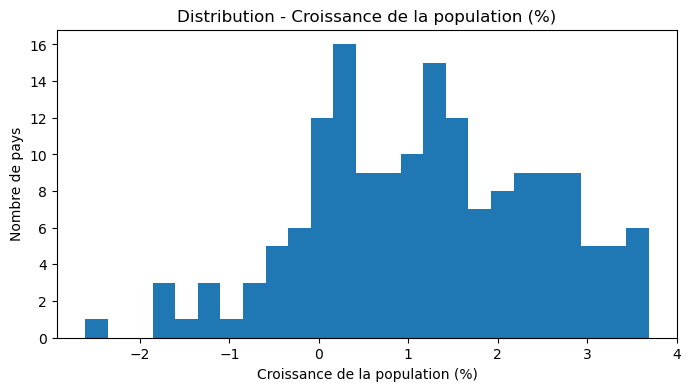

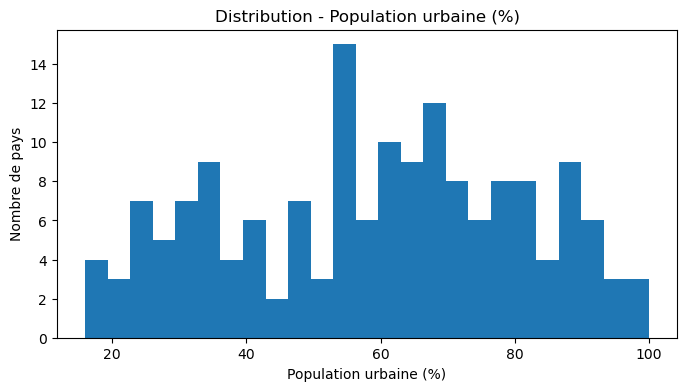

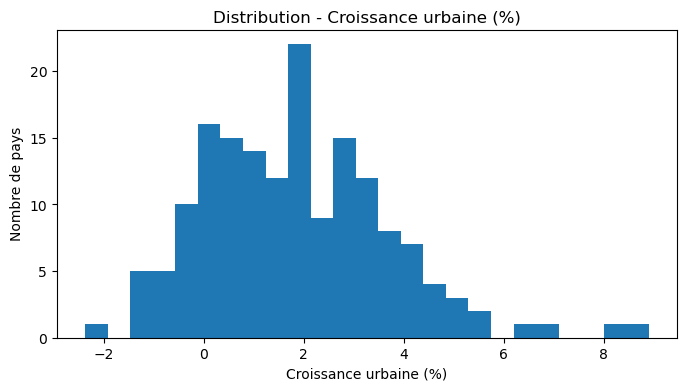

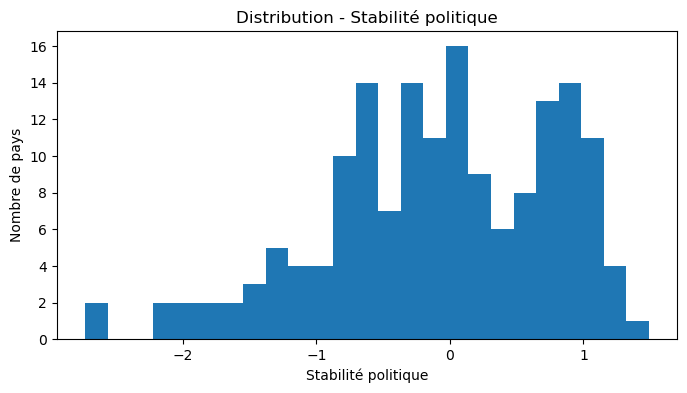

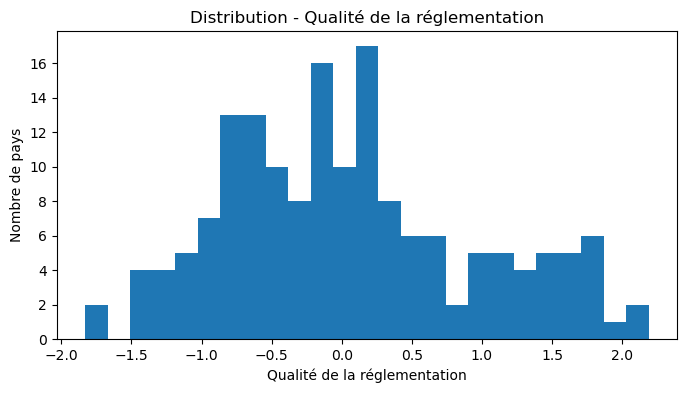

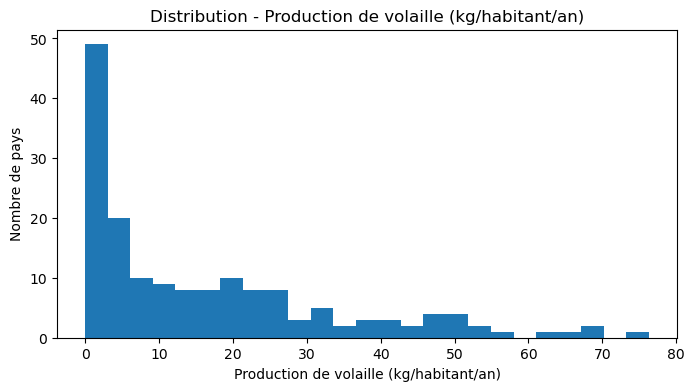

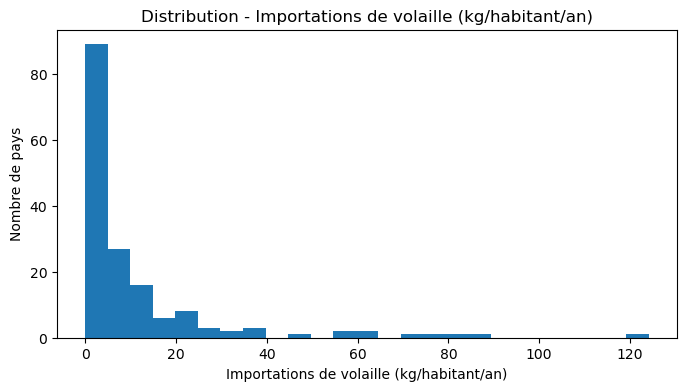

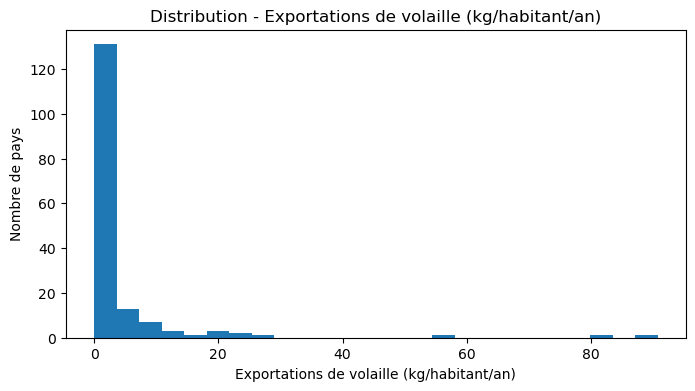

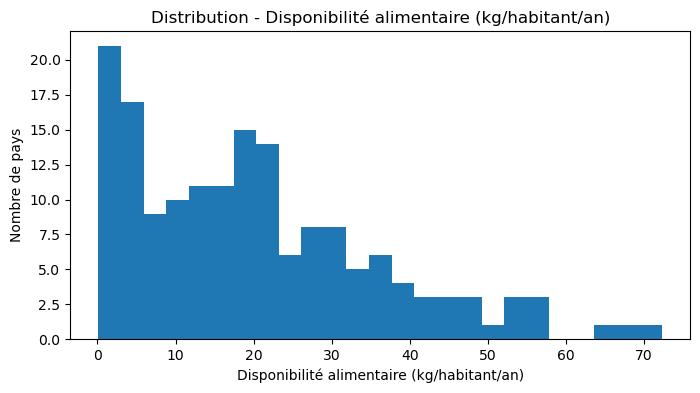

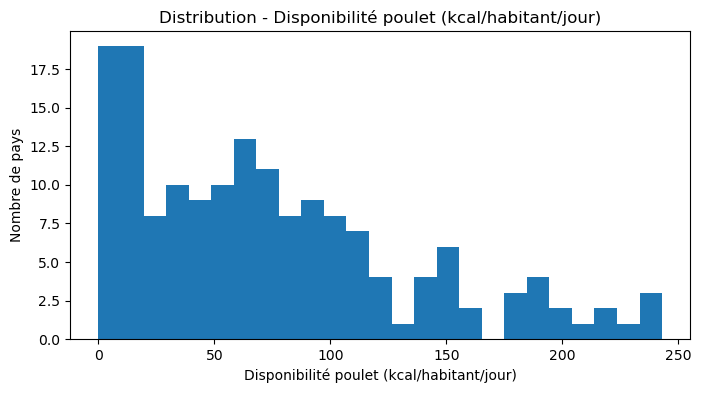

In [19]:
import matplotlib.pyplot as plt

variables = {
    'PIB_hab': 'PIB par habitant (USD)',
    'Croissance_Pop': 'Croissance de la population (%)',
    'Urbanisation': 'Population urbaine (%)',
    'Croissance_Urb': 'Croissance urbaine (%)',
    'Stabilite_Politique': 'Stabilité politique',
    'Qualite_Regulation': 'Qualité de la réglementation',
    'Production_volaille_hab': 'Production de volaille (kg/habitant/an)',
    'Importations_volaille_hab': 'Importations de volaille (kg/habitant/an)',
    'Exportations_volaille_hab': 'Exportations de volaille (kg/habitant/an)',
    'Disponibilite_alimentaire_kg_hab': 'Disponibilité alimentaire (kg/habitant/an)',
    'Poulet_Kcal_jour' : 'Disponibilité poulet (kcal/habitant/jour)'
}

for var, titre in variables.items():
    plt.figure(figsize=(8, 4))
    plt.hist(df_final[var], bins=25)
    plt.title(f'Distribution - {titre}')
    plt.xlabel(titre)
    plt.ylabel('Nombre de pays')
    plt.show()

Analyse des distributions

L’analyse des distributions met en évidence des profils très contrastés entre les variables, révélant des dynamiques économiques, démographiques et avicoles hétérogènes selon les pays.

Le PIB par habitant présente une asymétrie marquée : la majorité des pays se situent dans des niveaux de revenus faibles ou intermédiaires, tandis qu’un nombre limité de pays affichent des valeurs très élevées. Cette structure reflète une forte disparité économique mondiale.

Les variables liées aux échanges de volaille (importations et exportations) ainsi que la production montrent également une asymétrie importante. La plupart des pays présentent des niveaux très faibles, alors que quelques acteurs industriels se distinguent par des valeurs nettement supérieures. Ces variables sont donc fortement discriminantes pour la segmentation des marchés.

La disponibilité alimentaire en volaille est très dispersée : si de nombreux pays affichent une consommation faible, certains présentent des niveaux particulièrement élevés, révélant des marchés matures ou fortement consommateurs.
La population urbaine est plus équilibrée, bien que certains pays soient très urbanisés et d’autres majoritairement ruraux, ce qui crée des profils distincts en termes de demande et de structure de marché.

Les variables de croissance démographique et de croissance urbaine sont globalement concentrées autour de faibles taux, avec quelques valeurs extrêmes. Elles apportent une information complémentaire mais restent peu structurantes dans l’analyse.

Les indicateurs de stabilité politique et de qualité de la réglementation sont centrés autour de la moyenne, tout en présentant des écarts significatifs entre les pays. Ils permettent de distinguer les environnements institutionnels stables des contextes plus fragiles.

Plusieurs variables présentent des valeurs extrêmes, notamment le PIB par habitant, les importations totales et la production. 
Certains pays très atypiques (ex. Luxembourg, Émirats arabes unis, Hong Kong) créent des distributions fortement déséquilibrées et peuvent influencer l’ACP ou le clustering.
Pour limiter cet effet, on va appliquer une transformation logarithmique sur les variables les plus asymétriques, puis une standardisation afin d’harmoniser les échelles. 
Ces traitements réduisent l’impact des valeurs extrêmes et garantissent une analyse multivariée plus stable et interprétable.

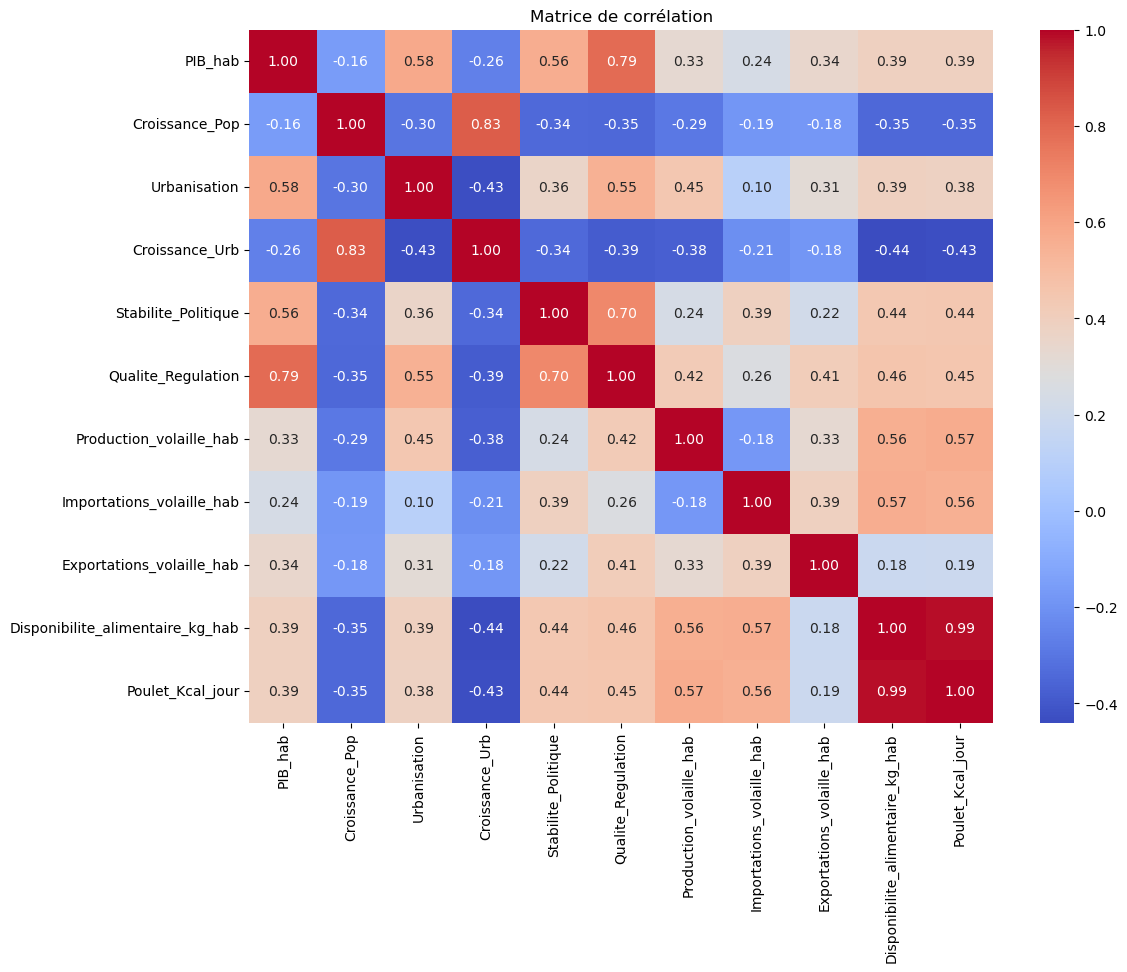

In [20]:
import seaborn as sns
import matplotlib.pyplot as plt

corr = df_final[list(variables.keys())].corr()

plt.figure(figsize=(12, 9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm')
plt.title('Matrice de corrélation')
plt.show()

Interprétation :
La matrice de corrélation met en évidence plusieurs relations entre les variables. 
La corrélation la plus forte concerne la croissance de la population et la croissance urbaine (0,83), indiquant une évolution généralement conjointe de ces deux phénomènes. 
Le PIB par habitant est également fortement corrélé à la qualité de la régulation (0,79) et, dans une moindre mesure, à la stabilité politique (0,56) et à l’urbanisation (0,58).

Enfin, la variable Poulet_Kcal_jour présente une distribution très proche de celle de la disponibilité alimentaire. En raison de leur corrélation extrêmement élevée, cette variable a été écartée de l’ACP afin d’éviter une sur‑pondération de la dimension “consommation”.

Concernant le secteur avicole, la disponibilité alimentaire par habitant est modérément corrélée aux importations (0,57) et à la production (0,56). La production et les exportations présentent également une corrélation positive (0,33).

Dans l’ensemble, les variables présentent des niveaux de corrélation variés, ce qui indique qu’elles apportent des informations complémentaires pour caractériser les pays. La matrice ne révèle pas de redondance excessive entre les variables retenues pour l’ACP. Les corrélations observées étant uniquement des associations statistiques, elles ne permettent pas d'établir de relations de causalité.

Conclusion : 
L'exploration des données met en évidence des profils économiques, démographiques, institutionnels et avicoles variés entre les pays. 
Certaines variables présentent une forte asymétrie et des valeurs extrêmes, tandis que plusieurs corrélations significatives sont observées. 
Le jeu de données apparaît ainsi suffisamment diversifié pour poursuivre l'analyse par une réduction dimensionnelle et une classification des pays.